# Thermal eclipse imaging: from one unresolved curve to a conditional surface map

## 1. Problem and trustworthy measurements

An opaque stellar limb scans an unresolved emitting planet. We reconstruct a32×64dayside brightness field, retaining the three most observable nonuniform spatial modes. This is an existing **author noiseless simulation with simulated uncertainty**, not measured JWST photometry and not known spatial truth. The exact126samples at3.31micrometres are actively reconstructed below. Original and fresh posterior means are different measurements of the same conditional method.

ACTUAL_KERNEL_ENVIRONMENT {"executable": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe", "python": "3.11.11 (main, Mar 17 2025, 21:01:29) [MSC v.1943 64 bit (AMD64)]", "os": "Windows-10-10.0.26200-SP0", "numpy": "2.4.6", "numpy_file": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Lib\\site-packages\\numpy\\__init__.py", "scipy": "1.17.1", "matplotlib": "3.11.1", "backend": "module://matplotlib_inline.backend_inline", "threads": {"OMP_NUM_THREADS": "1", "OPENBLAS_NUM_THREADS": "1", "MKL_NUM_THREADS": "1"}}


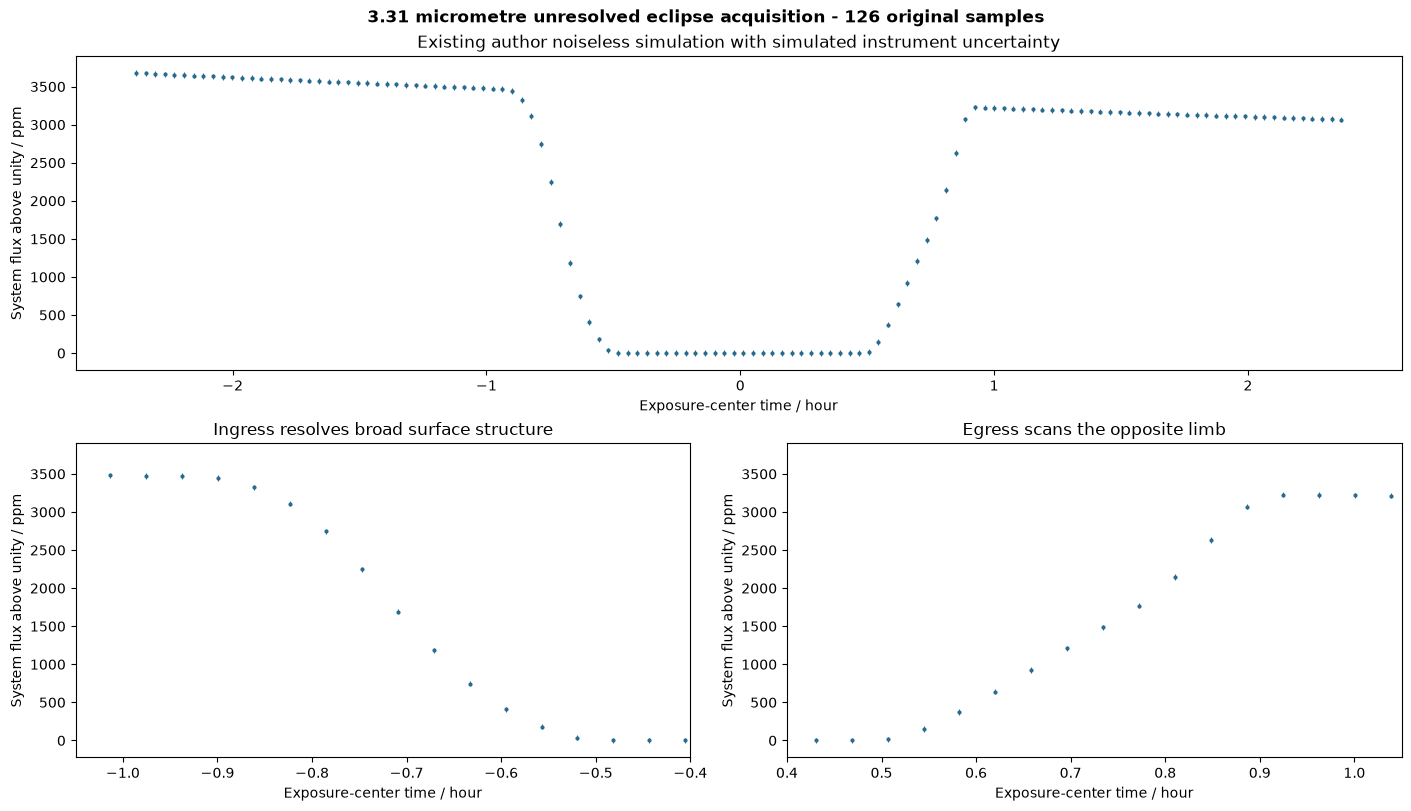

In [1]:
from pathlib import Path
import sys,time,json,os,platform
import numpy as np,scipy,matplotlib
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src import visualization as viz
env={'executable':sys.executable,'python':sys.version,'os':platform.platform(),'numpy':np.__version__,'numpy_file':np.__file__,'scipy':scipy.__version__,'matplotlib':matplotlib.__version__,'backend':matplotlib.get_backend(),'threads':{k:os.environ.get(k) for k in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']}}
print('ACTUAL_KERNEL_ENVIRONMENT '+json.dumps(env))
d=load_data(ROOT/'data/raw_data.npz')
def show(name,result):
    fig,numeric=result;plt.show();return numeric
acquisition=show('acquisition',viz.acquisition(d))

## 2. Acquisition physics and its spatial null directions

The forward model is $f(t)=b+sum_j a_j(t)I_j(t)$: tile areas are in squared planet radii, I is stellar-normalized surface brightness per unit projected area, and b is a constant stellar offset. Twenty annuli contain400equal-area sectors, each with midpoint brightness. The circular stellar occultor hides exact portions of those sectors. We independently integrate blocked radial intervals over polar angle, splitting at circle intersections; a sine-squared angular substitution regularizes tangency endpoints for64-point Gaussian quadrature. It evaluates the same selected discrete physics as the author C geometry, not a pixelized substitute.

The orbit includes inclination85.71degrees, period2.21857567days, Rp/Rstar.155313,a/Rstar8.863, synchronous rotation and the original light-time correction. Surface rotation uses the uncorrected phase while the occulting center uses the corrected phase, preserving the author's approximation. The local source explicitly computes geometry, nine real harmonics through degree2, area integrals, the16signed nonuniform light curves and their covariance eigenvectors. The first three modes define this task; weak modes remain physically underdetermined.

Fresh complete reconstruction seconds 0.5879361999977846
Minimum ESS 2242.270126426703 maximum tau 51.37650394673166 retained length / maximum tau 70.07094145083447


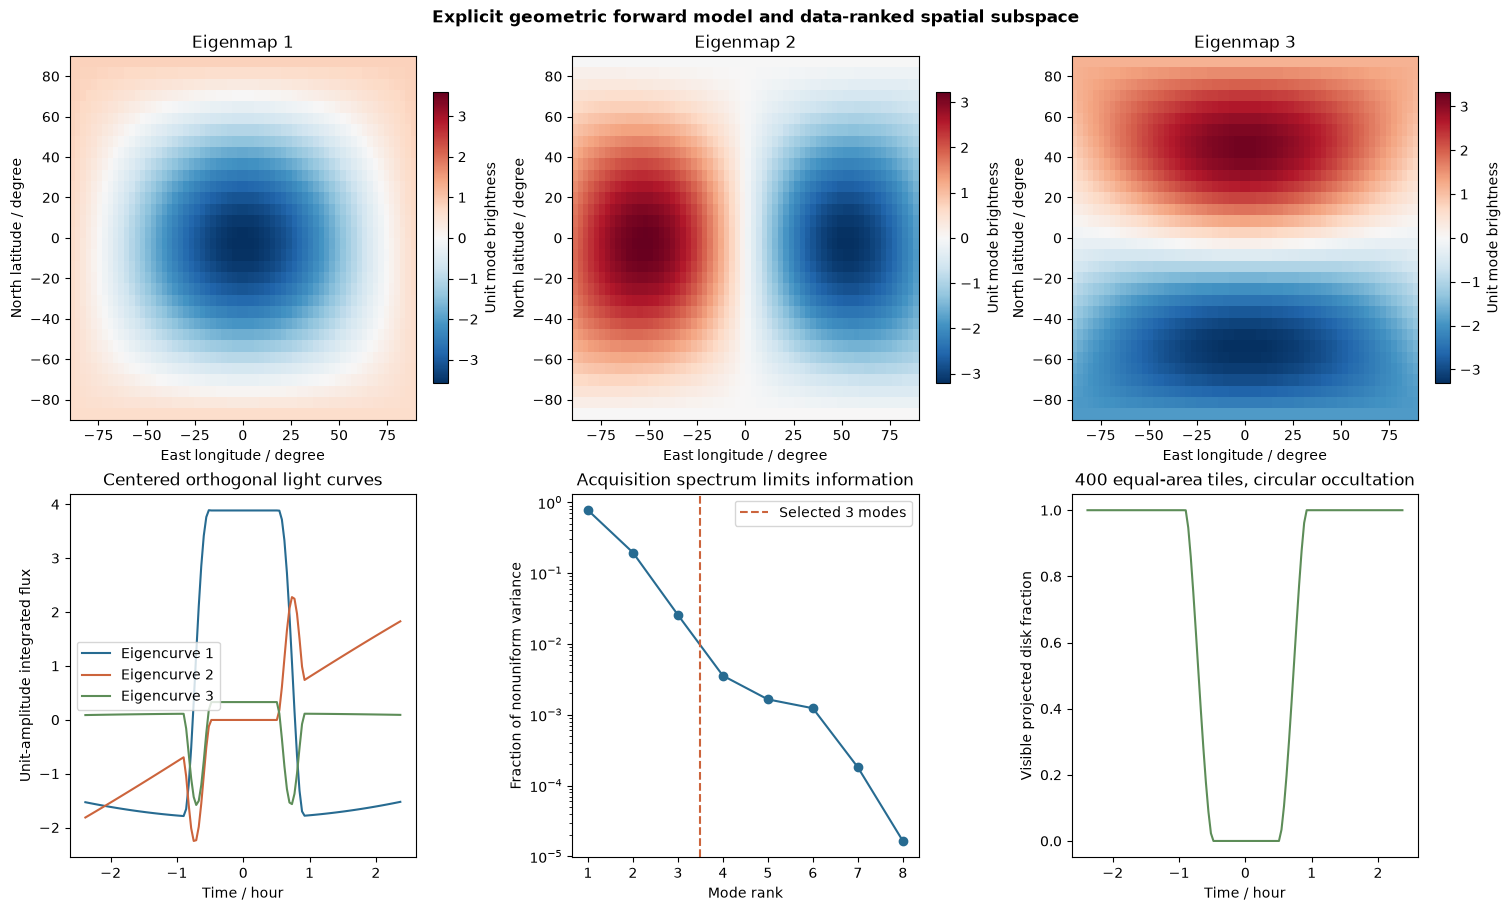

In [2]:
start=time.perf_counter();image,state=reconstruct(d);runtime=time.perf_counter()-start
print('Fresh complete reconstruction seconds',runtime)
print('Minimum ESS',state['effective_sample_size'].min(),'maximum tau',state['autocorrelation'].max(),'retained length / maximum tau',len(state['chain'])/state['autocorrelation'].max())
physics=show('physics',viz.physics(d,state))

## 3. Published inverse, explicit local updates and qualified original evidence

The three-mode design X consists of the uncentered uniform curve, a constant and three time-centered eigencurves. Its Gaussian log likelihood is

$$\log p(p\mid f)=-\tfrac12\sum_t[(f_t-(Xp)_t)^2/\sigma_t^2+\log(2\pi\sigma_t^2)]+\log\pi(p).$$

Here p contains uniform brightness c0, stellar offset b and three mode amplitudes; the prior is flat with c0,b>=0. There is no extra pixel clipping. Starting from the author's unweighted least-squares initializer (equivalent weighting because sigma is constant),32walkers are displaced by1e-5Gaussian draws. The explicit two-half ensemble sampler proposes $p'=q+z(p-q)$, with companion q in the other half and $z=[1+U]^2/2$,U uniform0..1; accept using $(D-1)\log z+\log p(p')-\log p(p)$, where D=5. We use4000steps and400burn-in, extending the supplied short-chain configuration to meet the paper's retained-length>50autocorrelation-time criterion. Samples transform linearly back to spherical brightness; the reported map is their mean.

The original selected justafew branch has the correct Gaussian likelihood and fixed3PCmodel. The other source branch contains floor-division in a model-selection diagnostic and is not silently substituted. Exact author C forward/map calculations run in private WSL subprocesses, with the original selected Python inverse in Windows. Two identified C memory-only defects are corrected (unused pointer initialization and borrowed-reference ownership), and a NumPy2scalar conversion uses item(). All failed original runs, original source and patch hashes are retained privately. No scientific equations or stretch transitions are changed. The original path is therefore **qualified**, not claimed unmodified. Three independent original chains are shown below.

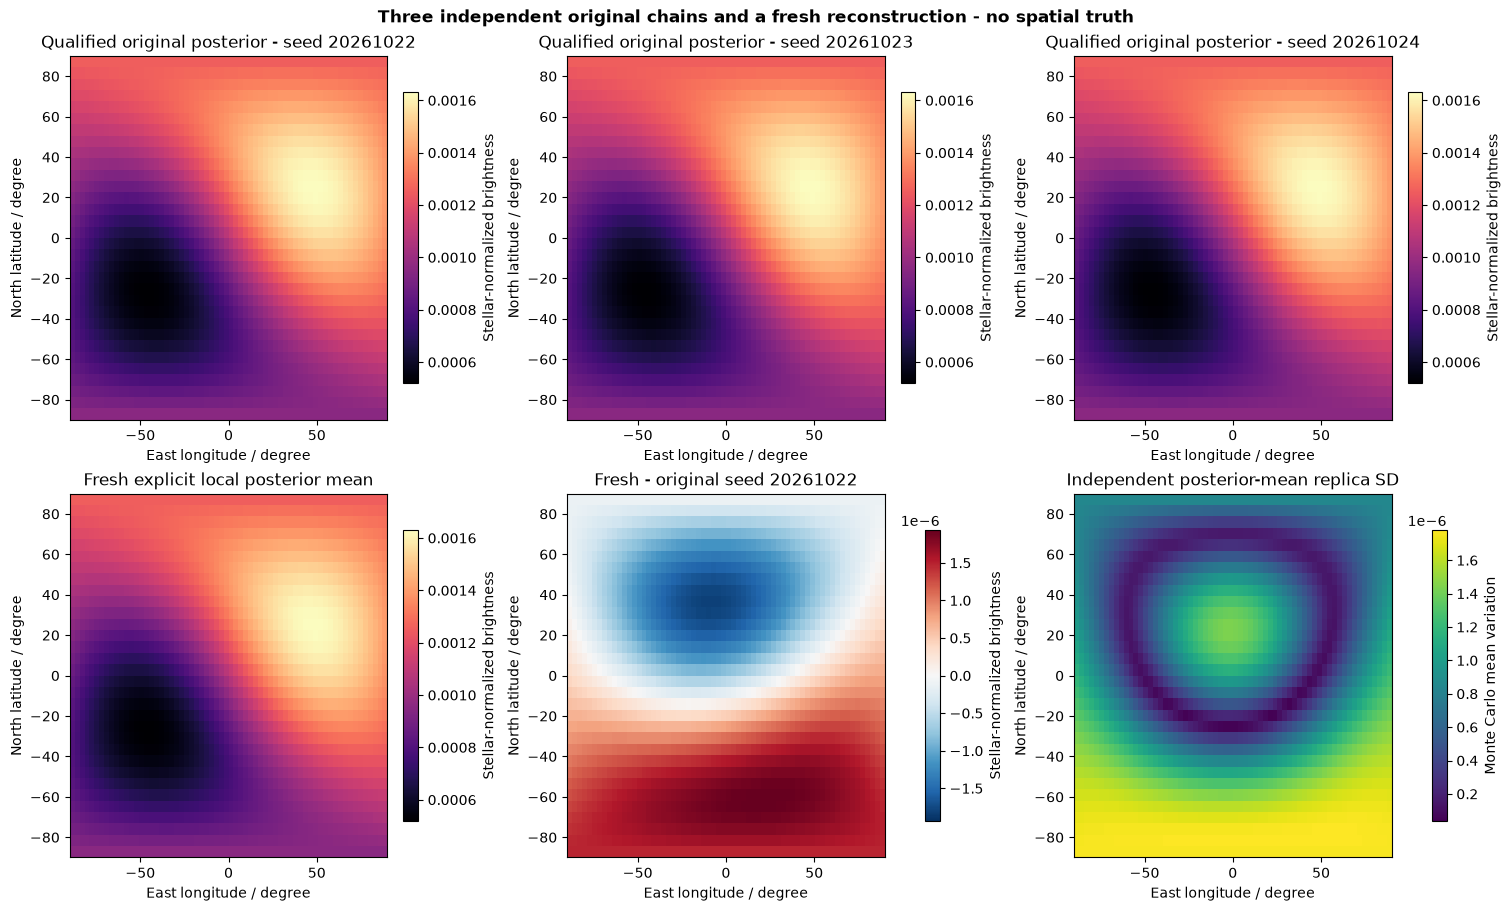

Fresh/original dynamic-range NRMSE by original chain [0.0010293467210332845, 0.0007946925250821759, 0.001065759683910108]


In [3]:
with np.load(ROOT/'notebooks/reference_outputs/upstream_posterior.npz',allow_pickle=False) as f:original={k:f[k] for k in f.files}
comparison=show('comparison',viz.comparison(d,image,original['mean_maps']))
print('Fresh/original dynamic-range NRMSE by original chain',[float(np.sqrt(np.mean((image-a)**2))/np.ptp(a)) for a in original['mean_maps']])

## 4. Fresh predicted measurements and honest model mismatch

We recompute both the complete three-mode prediction and a least-squares uniform-map comparison. The input contains no added random noise, so residuals are primarily selected-model truncation and acquisition approximation mismatch. A standardized RMS near2is not a photon-noise validation or an independently correct atmosphere. The source's three-mode conditional model is intentionally preserved. Original C geometry and local mathematics agree in all17basis curves at numerical precision, while the inversion cannot make an inadequate spatial subspace physically exact.

Evaluation scores the entire map against the identified original posterior mean, with nonzero Monte Carlo tolerance measured from independent chains. A separate forward check projects the map onto the declared degree-two harmonics and fits only the constant stellar nuisance offset. It applies no spatial alignment, scale or additive map correction.

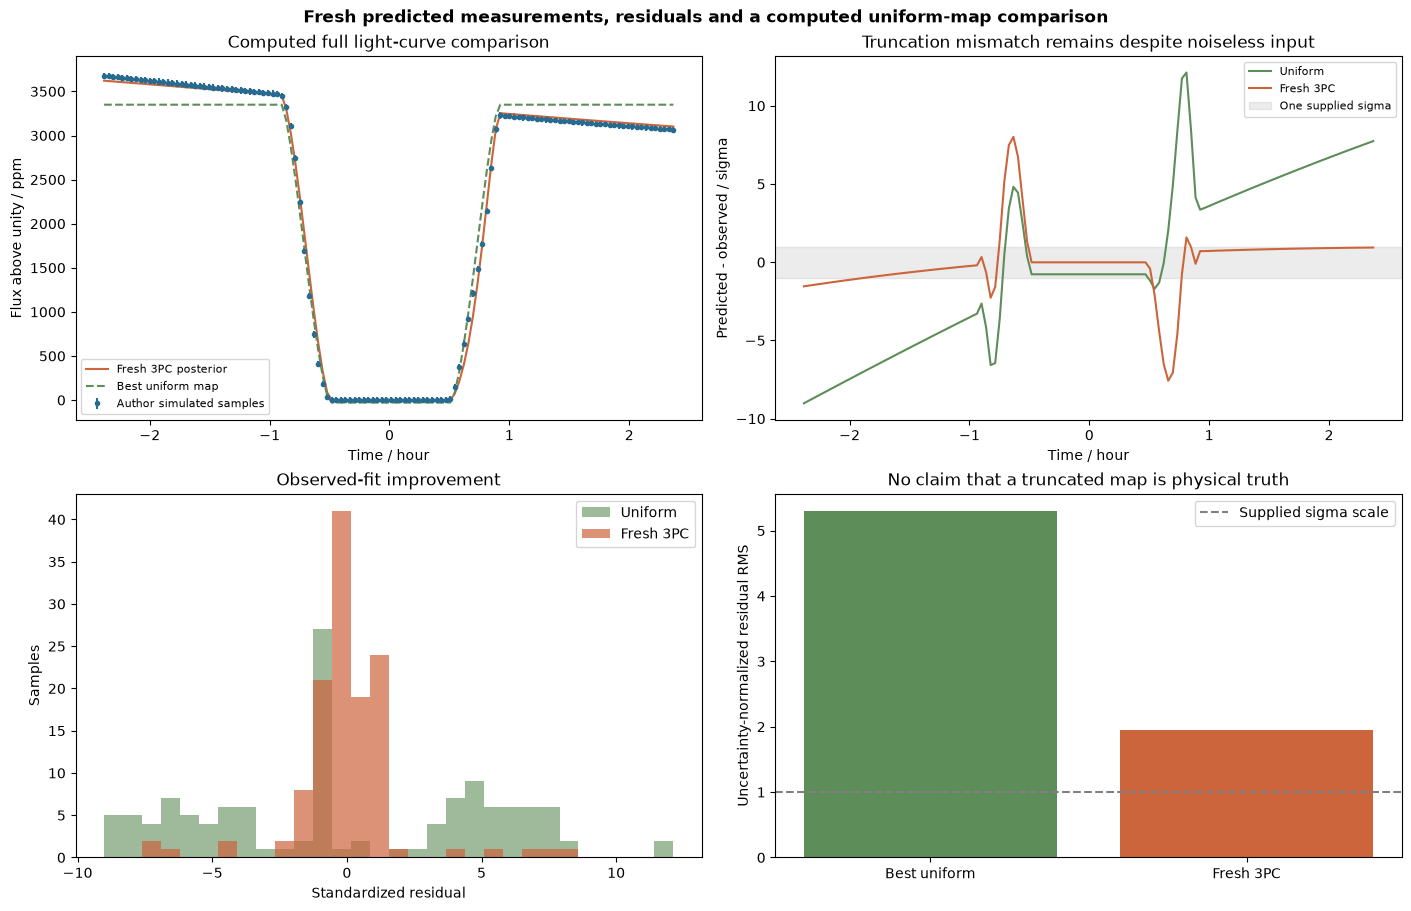

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "reconstruction_ncc": 0.9999994951602726,
    "reconstruction_nrmse": 0.0010293467210332845,
    "standardized_observation_rms": 1.95004072628003
  },
  "thresholds": {
    "reconstruction_ncc": {
      "comparison": ">=",
      "boundary": 0.9999
    },
    "reconstruction_nrmse": {
      "comparison": "<=",
      "boundary": 0.005
    },
    "standardized_observation_rms": {
      "comparison": "<=",
      "boundary": 2.05
    }
  },
  "errors": []
}


In [4]:
residuals=show('residuals',viz.residuals(d,state))
out=ROOT/'output/reconstruction.npz';np.savez_compressed(out,reconstruction=image[None])
np.savez_compressed(ROOT/'notebooks/reference_outputs/cleaned_measurements.npz',reconstruction=image[None],prediction=state['prediction'],mean_parameters=state['mean_parameters'],autocorrelation=state['autocorrelation'],effective_sample_size=state['effective_sample_size'])
import subprocess
r=subprocess.run([sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(out),'--report',str(ROOT/'output/judge_report.json')],capture_output=True,text=True)
print((ROOT/'output/judge_report.json').read_text());assert r.returncode==0,r.stderr

## 5. Convergence, uncertainty and model-order sensitivity

Autocorrelation and effective sample sizes are computed from actual retained chains. Three independent original chains and the fresh local chain each exceed50times their largest autocorrelation time. Because this is a linear Gaussian problem with nonbinding nonnegative c0,bpriors, an independently solved Gaussian mean/covariance supplies a second posterior check. It validates sampling accuracy without pretending the full spatial field is identifiable. Posterior map standard deviation propagates the parameter covariance through local real harmonics.

The following five active refits retain1through5eigencurves with the same sampler configuration. They expose the tradeoff between curve fit and map structure; these are explicitly different model-order comparisons, not alternate methods substituted into the standard three-mode result. More modes may lower residuals while increasing poorly determined spatial structure.

All 3 original whole-ensemble autocorrelation replay maximum error 1.482121092521993e-10
Original max tau, minimum retained length/tau, minimum ESS [[  51.85676068   69.42199923 2221.50397551]
 [  53.96586859   66.70883086 2134.68258746]
 [  56.87613023   63.29544548 2025.45425547]]
Fresh max tau, retained length/tau, minimum ESS 51.37650394673166 70.07094145083447 2242.270126426703
Original independent mean parameters [[1.12065720e-03 9.99871367e-01 2.47779626e-05 1.42718635e-04
  9.65934036e-05]
 [1.12188443e-03 9.99868718e-01 2.55497292e-05 1.42758832e-04
  9.60170774e-05]
 [1.12224652e-03 9.99867790e-01 2.56648009e-05 1.42758259e-04
  9.59936800e-05]]
Fresh / mean original parameter variance [0.98953723 0.98953828 0.98760198 0.99082722 1.04217979]
Independent original C map projection standardized RMS, fitted stellar offset only 1.9500501833443145
Original direct C map / analytic harmonic consistency 8.673617379884035e-19


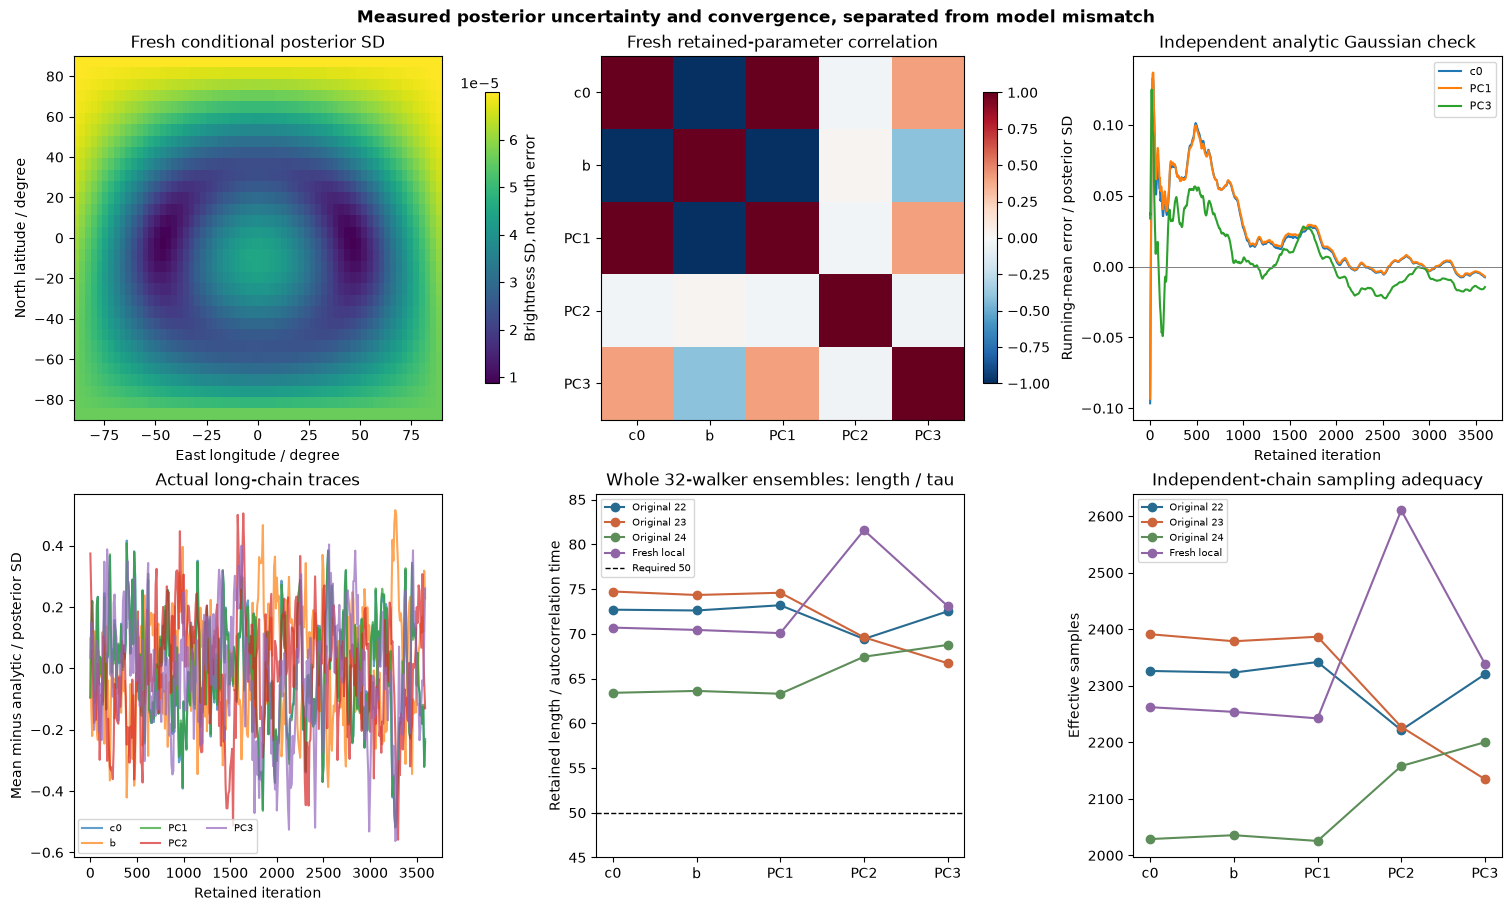

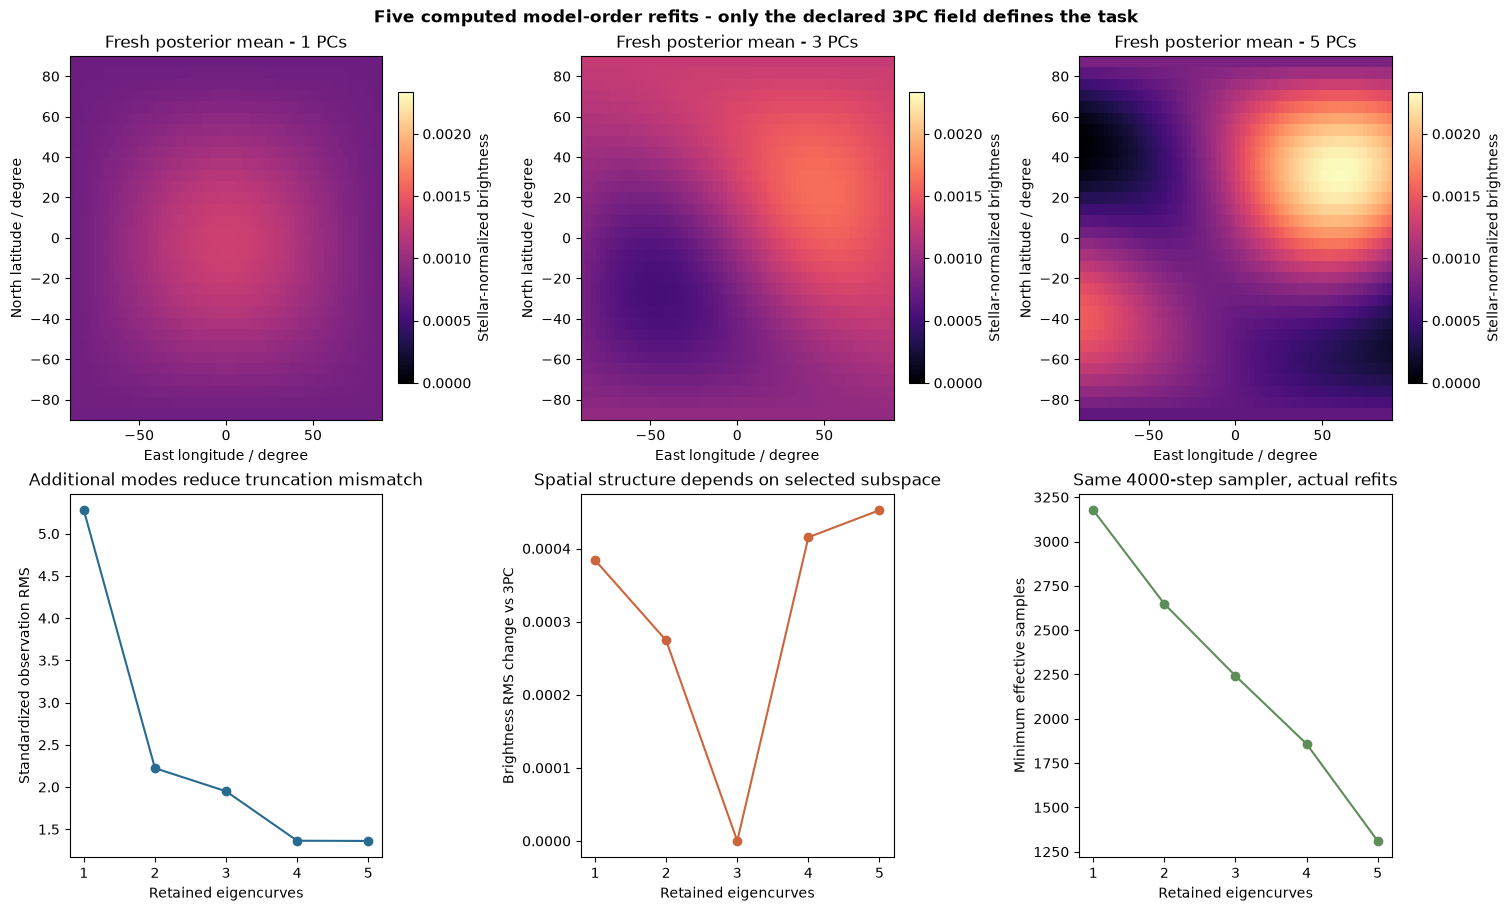

Computed model-order standardized RMS [5.27780511 2.22375388 1.9500408  1.36455956 1.36161791]


In [5]:
from src.solvers import autocorrelation_time
replayed_tau=np.array([autocorrelation_time(chain) for chain in original['chains']])
print('All 3 original whole-ensemble autocorrelation replay maximum error',float(np.max(abs(replayed_tau-original['autocorrelation']))));assert np.allclose(replayed_tau,original['autocorrelation'],rtol=1e-12,atol=1e-10)
print('Original max tau, minimum retained length/tau, minimum ESS',np.column_stack([replayed_tau.max(axis=1),original['retained_lengths']/replayed_tau.max(axis=1),original['retained_lengths']*original['walkers']/replayed_tau.max(axis=1)]))
print('Fresh max tau, retained length/tau, minimum ESS',state['autocorrelation'].max(),len(state['chain'])/state['autocorrelation'].max(),state['effective_sample_size'].min())
print('Original independent mean parameters',original['mean_parameters'])
print('Fresh / mean original parameter variance',np.var(state['chain'].reshape(-1,5),axis=0,ddof=1)/np.diagonal(original['covariances'],axis1=1,axis2=2).mean(axis=0))
with np.load(ROOT/'notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False) as f:upstream={k:f[k] for k in f.files}
original_curve=upstream['prediction'];offset=np.mean(d['measurements']-original_curve)
print('Independent original C map projection standardized RMS, fitted stellar offset only',float(np.sqrt(np.mean(((original_curve+offset-d['measurements'])/d['uncertainty'])**2))))
from src.physics_model import harmonics
print('Original direct C map / analytic harmonic consistency',float(np.max(abs(harmonics(d['latitude'],d['longitude'])@upstream['mean_coefficients']-upstream['reconstruction'][0]))))
posterior=show('posterior',viz.posterior(d,state,original))
sensitivity=show('sensitivity',viz.sensitivity(d,image))
print('Computed model-order standardized RMS',sensitivity['standardized_rms'])

## 6. Conclusion and reproducibility limits

The shipped method actively reconstructs a spatial thermal brightness field from the exact author-simulated acquisition and agrees with independent long original chains. Explicit local geometry, harmonic normalization, PCA, likelihood, stretch moves and posterior transformation replace all domain-library calls. The standalone Judge and tests separately verify contracts, numerical stages, analytic occultation area, Gaussian posterior behavior and poor-map rejection.

This is a conditional three-mode map, not physical atmospheric truth. Finite disk tiles, point-time exposure approximation, selected harmonic order and only one thermal wavelength limit interpretation. Simulated error bars describe an assumed instrument; no real JWST observation is claimed. Original qualification and memory fixes are documented rather than concealed. Canonical outputs, actual kernel and computed comparisons remain embedded here; scientific export figures and numerical plot sources are archived privately.